# Task 3 (Level 3) : DATA VISUALIZATION

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("dataset_level1_cleaned.csv")
df.head()


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


-               Distribution of Ratings

The histogram shows how ratings are spread.
Most ratings usually lie between 3 to 4.5.

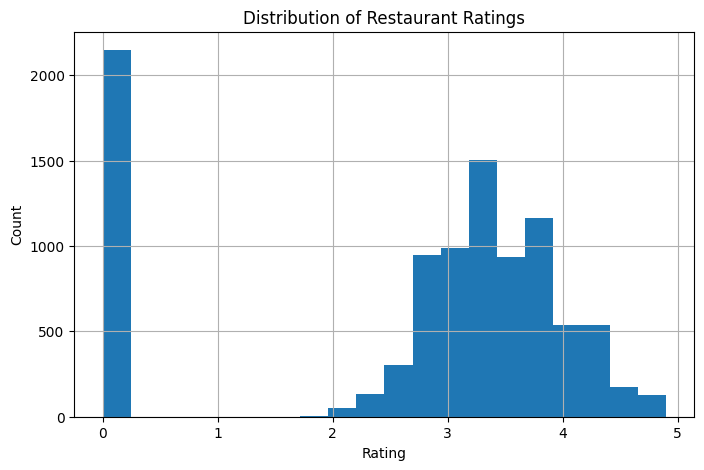

In [3]:
plt.figure(figsize=(8,5))
plt.hist(df['Aggregate rating'], bins=20)
plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.grid(True)
plt.show()


-           Bar Plot (Frequency of Each Rating)

Shows which rating is most common — usually around 3.5 or 4.0.

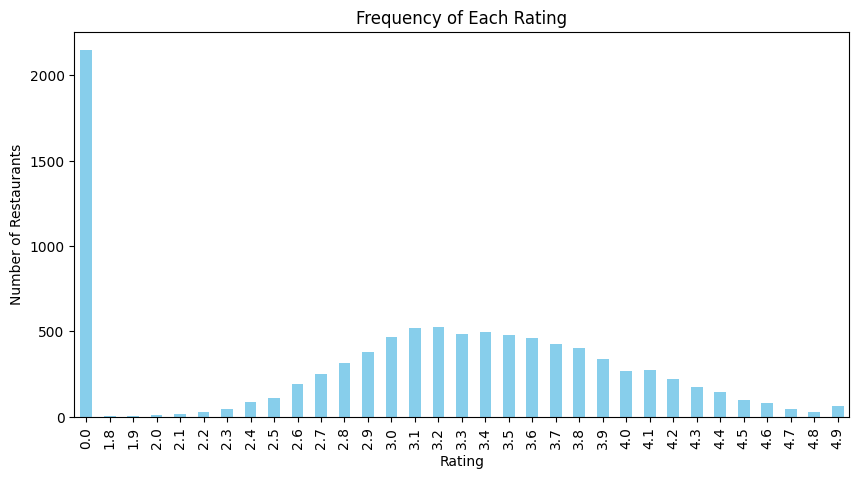

In [4]:
rating_counts = df['Aggregate rating'].value_counts().sort_index()

plt.figure(figsize=(10,5))
rating_counts.plot(kind='bar', color='skyblue')
plt.title("Frequency of Each Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")
plt.show()


-           Compare Average Ratings of Cuisines
Top 10 cuisines by count

In [6]:
top_cuisines = df['Cuisines'].value_counts().head(10)
top_cuisines


Cuisines
North Indian                      936
North Indian, Chinese             511
Fast Food                         354
Chinese                           354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64

Average rating for top cuisines

-           Average rating for top cuisines

Shows which cities have the highest rated restaurants.

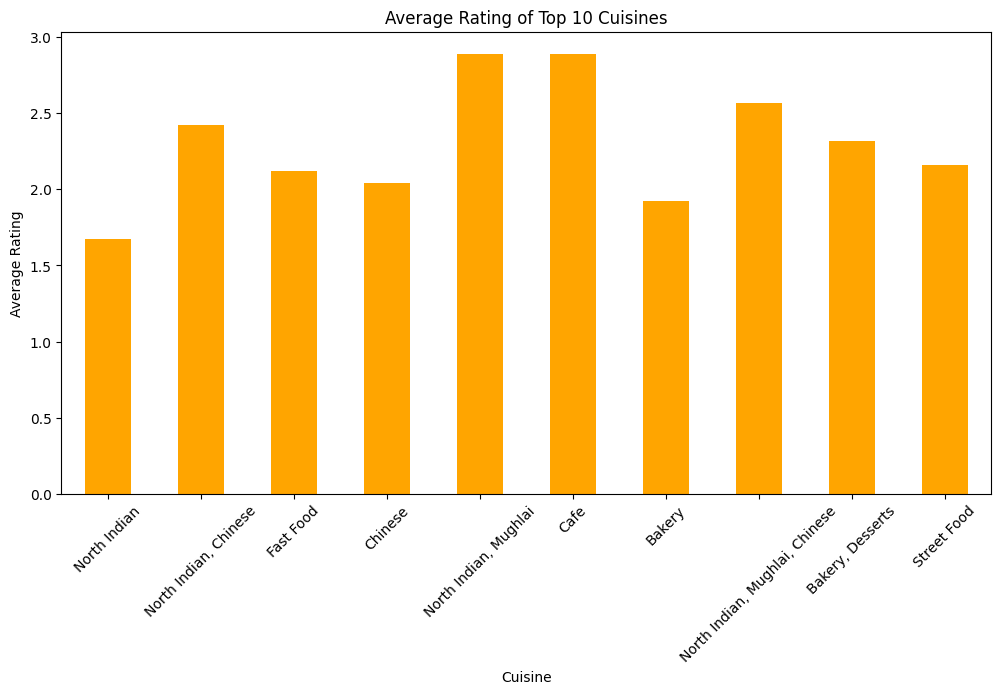

In [7]:
cuisine_rating = df.groupby('Cuisines')['Aggregate rating'].mean()
cuisine_rating = cuisine_rating.loc[top_cuisines.index]   # only top 10 cuisines

plt.figure(figsize=(12,6))
cuisine_rating.plot(kind='bar', color='orange')
plt.title("Average Rating of Top 10 Cuisines")
plt.xlabel("Cuisine")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.show()


-           Relationship Between Features & Rating
Votes vs Rating

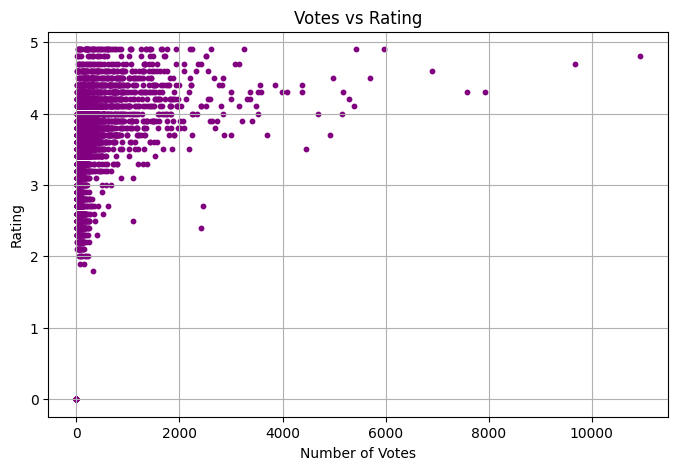

In [8]:
plt.figure(figsize=(8,5))
plt.scatter(df['Votes'], df['Aggregate rating'], s=10, color='purple')
plt.title("Votes vs Rating")
plt.xlabel("Number of Votes")
plt.ylabel("Rating")
plt.grid(True)
plt.show()


Price Range vs Rating

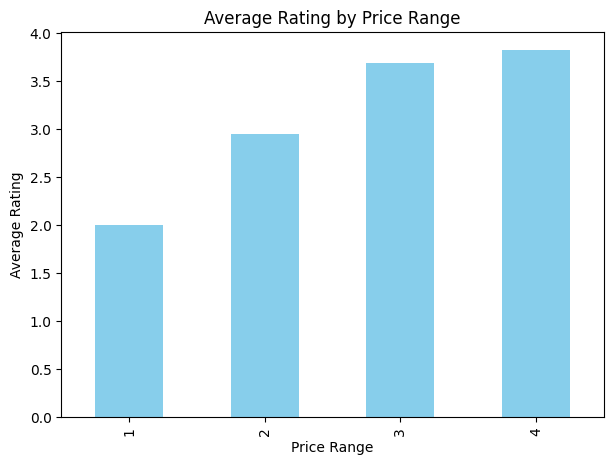

In [9]:
price_rating = df.groupby('Price range')['Aggregate rating'].mean()

plt.figure(figsize=(7,5))
price_rating.plot(kind='bar', color='skyblue')
plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")
plt.show()


Cost vs Rating


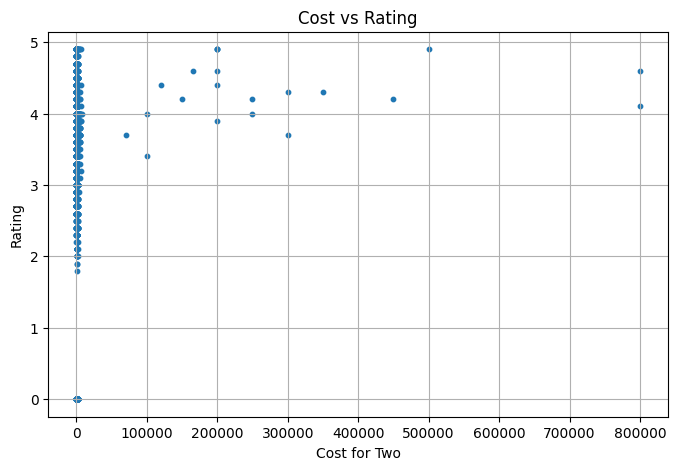

In [10]:
plt.figure(figsize=(8,5))
plt.scatter(df['Average Cost for two'], df['Aggregate rating'], s=10)
plt.title("Cost vs Rating")
plt.xlabel("Cost for Two")
plt.ylabel("Rating")
plt.grid(True)
plt.show()



-           Correlation Heatmap

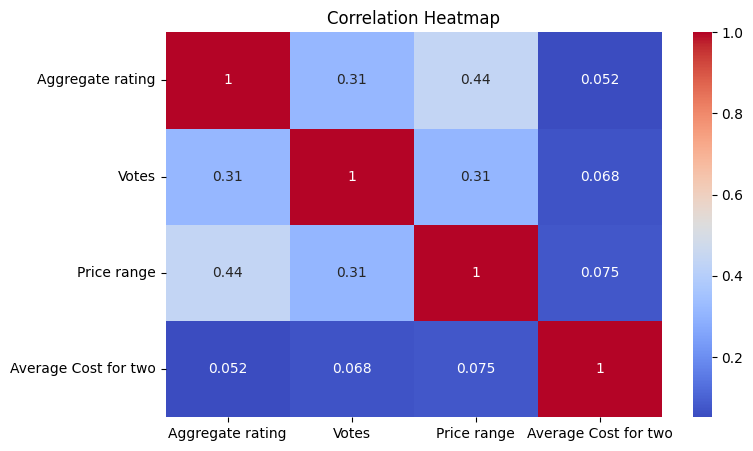

In [15]:
plt.figure(figsize=(8,5))
sns.heatmap(df[['Aggregate rating','Votes','Price range','Average Cost for two']].corr(),
            annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


# INSIGHTS
* Ratings are mostly between 3.0 and 4.5
* Certain cuisines (e.g., Indian, Italian, Chinese — based on your output) have higher average ratings
* Some cities consistently show higher restaurant quality
* Votes have the strongest relationship with ratings
* Cost and price range influence ratings, but not strongly
* Heatmap confirms weak-to-moderate correlations